# Nota para mi: Primera Competencia (titulo: exp 6005 (copiando mi notebook original de google collab))

**Originalmente lo corri en VS Code y dio 107,97 en el bot, no hice ningun cambio al modelo y tiene 
aguinaldo + lags y deltas **de orden 1**, Bayesian Optimization de 30 iteraciones, 25% de los CONTINUA, 10 semillas.

Nota para despues de probar en el bot: hacer ensambles



In [1]:
BASE <- path.expand("~/buckets/b1")   # bucket de Google Cloud (persistente)

dir.create(file.path(BASE, "datasets"), recursive= TRUE, showWarnings= FALSE)
dir.create(file.path(BASE, "exp"),      recursive= TRUE, showWarnings= FALSE)

# URL del dataset 2026
archivo_origen  <- "https://storage.googleapis.com/open-courses/dmeyf2026-9c6f/competencia_01_crudo.csv"
archivo_destino <- file.path(BASE, "datasets", "competencia_01_crudo.csv")

options(timeout= 3600)   # el archivo es grande; por defecto R corta a los 60 segundos

if (!file.exists(archivo_destino) || file.size(archivo_destino) == 0)
  download.file(archivo_origen, archivo_destino, mode= "wb")

cat("Carpeta de trabajo:", BASE, "\n")
cat("Dataset:", round(file.size(archivo_destino) / 1e6), "MB\n")

Carpeta de trabajo: /home/ds/buckets/b1 
Dataset: 493 MB


## Genero mi clase ternaria primero 


In [2]:
require( "data.table" )

# leo el dataset
dataset <- fread(file.path(BASE, "datasets", "competencia_01_crudo.csv") )

# calculo el periodo0 consecutivo
dsimple <- dataset[, list(
    "pos" = .I,
    numero_de_cliente,
    periodo0 = as.integer(foto_mes/100)*12 +  foto_mes%%100 ) ]

# ordeno
setorder( dsimple, numero_de_cliente, periodo0 )

# calculo topes
periodo_ultimo <- dsimple[, max(periodo0) ]
periodo_anteultimo <- periodo_ultimo - 1

# calculo los leads de orden 1 y 2
dsimple[, c("periodo1", "periodo2") :=
    shift(periodo0, n=1:2, fill=NA, type="lead"),  numero_de_cliente ]

# assign most common class values = "CONTINUA"
dsimple[ periodo0 < periodo_anteultimo, clase_ternaria := "CONTINUA" ]

# calculo BAJA+1
dsimple[ periodo0 < periodo_ultimo &
    ( is.na(periodo1) | periodo0 + 1 < periodo1 ),
    clase_ternaria := "BAJA+1" ]

# calculo BAJA+2
dsimple[ periodo0 < periodo_anteultimo & (periodo0+1 == periodo1 )
    & ( is.na(periodo2) | periodo0 + 2 < periodo2 ),
    clase_ternaria := "BAJA+2" ]

# pego el resultado en el dataset original y grabo
setorder( dsimple, pos )
dataset[, clase_ternaria := dsimple$clase_ternaria ]

fwrite( dataset,
    file =  file.path(BASE, "datasets", "competencia_01.csv.gz"),
    sep = ","
)

Loading required package: data.table


Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%




In [3]:
setorder( dataset, foto_mes, clase_ternaria, numero_de_cliente)
dataset[, .N, list(foto_mes, clase_ternaria)]

foto_mes,clase_ternaria,N
<int>,<chr>,<int>
202103,BAJA+1,1019
202103,BAJA+2,960
202103,CONTINUA,160921
202104,BAJA+1,964
202104,BAJA+2,1139
202104,CONTINUA,161181
202105,BAJA+1,1143
202105,BAJA+2,870
202105,CONTINUA,161755


## Inicio y parámetros (notebook del repositorio de las clases de los jueves)

In [4]:
format(Sys.time(), "%a %b %d %X %Y")

# limpio la memoria
rm(list= setdiff(ls(all.names=TRUE), "BASE")) # remove all objects, salvo BASE
gc(full=TRUE, verbose=FALSE) # garbage collection

[1] "Tue Oct 06 23:09:40 2026"

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,741827,39.7,1479650,79.1,1479650,79.1
Vcells,1392437,10.7,170860637,1303.6,212616731,1622.2


In [5]:
# cargo las librerias que necesito
require("data.table")
require("parallel")

if(!require("R.utils")) install.packages("R.utils")
require("R.utils")

if( !require("primes") ) install.packages("primes")
require("primes")

if( !require("utils") ) install.packages("utils")
require("utils")

if( !require("rlist") ) install.packages("rlist")
require("rlist")

if( !require("yaml")) install.packages("yaml")
require("yaml")

if( !require("lightgbm") ) install.packages("lightgbm")
require("lightgbm")

if( !require("DiceKriging") ) install.packages("DiceKriging")
require("DiceKriging")

if( !require("mlrMBO") ) install.packages("mlrMBO")
require("mlrMBO")

Loading required package: parallel

Loading required package: R.utils

Loading required package: R.oo

Loading required package: R.methodsS3

R.methodsS3 v1.8.2 (2022-06-13 22:00:14 UTC) successfully loaded. See ?R.methodsS3 for help.

R.oo v1.27.1 (2025-05-02 21:00:05 UTC) successfully loaded. See ?R.oo for help.


Attaching package: ‘R.oo’


The following object is masked from ‘package:R.methodsS3’:

    throw


The following objects are masked from ‘package:methods’:

    getClasses, getMethods


The following objects are masked from ‘package:base’:

    attach, detach, load, save


R.utils v2.13.0 (2025-02-24 21:20:02 UTC) successfully loaded. See ?R.utils for help.


Attaching package: ‘R.utils’


The following object is masked from ‘package:utils’:

    timestamp


The following objects are masked from ‘package:base’:

    cat, commandArgs, getOption, isOpen, nullfile, parse, use, warnings


Loading required package: primes

Loading required package: rlist

Loading required packa

###  Definicion de Parametros
aqui debe cargar SU semilla primigenia
<br>**recuerde cambiar el numero de experimento en cada corrida nueva**

In [6]:
PARAM <- list()
PARAM$experimento <- 6005   # el 5002 corrido en Google Cloud

PARAM$semillaprimigenia <- 992720

# semillas para los modelos finales: un archivo de Zulip por semilla (maximo 20 por submit)
PARAM$semillas <- c(
  864203, 451997, 909131, 582314, 737281,
  128945, 675432, 390217, 842691, 519804
)

**Meses.** Ajustar según la tabla de la sección 2. Dataset 2026: meses 202103 a 202108, futuro 202108:
- `eval_mes` = último mes con BAJA+2 conocido (202106) → donde se mide la ganancia local y la BO.
- `train` = meses anteriores a `eval_mes` → entrenamiento para BO y evaluación local.
- `train_final` = `train` + `eval_mes` → entrenamiento de los modelos que predicen el futuro.
- `future` = mes a predecir y entregar.

202107 **no** se usa para entrenar: todavía no se sabe quién de ese mes es BAJA+2.

In [7]:
# -------------------------------------------
# Períodos de entrenamiento, evaluación y futuro
# -------------------------------------------
PARAM$train       <- c(202103, 202104, 202105)   # el dataset 2026 arranca en 202103
PARAM$eval_mes    <- c(202106)
PARAM$train_final <- c(PARAM$train, PARAM$eval_mes)
PARAM$future      <- c(202108)

# cortes (cantidad de envíos) que se evaluan localmente
PARAM$cortes_eval <- seq(8000, 15000, by= 250)

# cortes para los archivos de Zulip
# NULL = se eligen solos alrededor del mejor corte de la evaluación local
PARAM$envios_zulip <- NULL

In [8]:
# un undersampling de 0.1  toma solo el 10% de los CONTINUA
# undersampling de 1.0  implica tomar TODOS los datos
# undersampling: Bayesian Optimization
PARAM$trainingstrategy$undersampling <- 0.25

# undersampling: evaluacion local y modelos finales
#  1.0 = todos los datos (necesita 16 GB de RAM o mas)
#  0.25 = version liviana para una compu con 8 GB
PARAM$trainingstrategy$undersampling_final <- 0.25

# lags y deltas de orden 2: FALSE para ahorrar memoria (8 GB)
PARAM$fe$lag2 <- FALSE

In [9]:
# Parametros LightGBM

# parametros fijos del LightGBM que se pisaran con la parte variable de la BO
PARAM$lgbm$param_fijos <-  list(
  boosting= "gbdt", # puede ir  dart  , ni pruebe random_forest
  objective= "binary",
  metric= "auc",
  first_metric_only= FALSE,
  boost_from_average= TRUE,
  feature_pre_filter= FALSE,
  force_row_wise= TRUE, # para reducir warnings
  verbosity= -100,

  seed= PARAM$semillaprimigenia,

  max_depth= -1L, # -1 significa no limitar,  por ahora lo dejo fijo
  min_gain_to_split= 0, # min_gain_to_split >= 0
  min_sum_hessian_in_leaf= 0.001, #  min_sum_hessian_in_leaf >= 0.0
  lambda_l1= 0.0, # lambda_l1 >= 0.0
  lambda_l2= 0.0, # lambda_l2 >= 0.0
  max_bin= 31L, # lo debo dejar fijo, no participa de la BO

  bagging_fraction= 1.0, # 0.0 < bagging_fraction <= 1.0
  pos_bagging_fraction= 1.0, # 0.0 < pos_bagging_fraction <= 1.0
  neg_bagging_fraction= 1.0, # 0.0 < neg_bagging_fraction <= 1.0
  is_unbalance= FALSE, #
  scale_pos_weight= 1.0, # scale_pos_weight > 0.0

  drop_rate= 0.1, # 0.0 < neg_bagging_fraction <= 1.0
  max_drop= 50, # <=0 means no limit
  skip_drop= 0.5, # 0.0 <= skip_drop <= 1.0

  extra_trees= FALSE,

  num_iterations= 1000,
  learning_rate= 0.02,
  feature_fraction= 0.5,
  num_leaves= 150,
  min_data_in_leaf= 500
)

Hiperparámetros que participan de la Bayesian Optimization
<br> si es un numero entero debe ir  makeIntegerParam
<br> si es un numero real (con decimales) debe ir  makeNumericParam

In [10]:
# Aqui se cargan los bordes de los hiperparametros de la BO
PARAM$hypeparametertuning$hs <- makeParamSet(
  makeIntegerParam("num_iterations", lower= 300L, upper= 2000L),
  makeNumericParam("learning_rate", lower= 0.01, upper= 0.1),
  makeNumericParam("feature_fraction", lower= 0.1, upper= 1.0),
  makeIntegerParam("num_leaves", lower= 20L, upper= 1024L),
  makeIntegerParam("min_data_in_leaf", lower= 20L, upper= 3000L)
)

In [11]:
PARAM$hyperparametertuning$iteraciones <- 30 # iteraciones bayesianas

# cuantas semillas usa CADA iteracion de la BO (1 o 2; mas semillas = mucho mas lento)
PARAM$hyperparametertuning$cant_semillas <- 2

### Funciones auxiliares

In [12]:
# ganancia acumulada: ordeno de mayor a menor probabilidad
#  y voy sumando +780000 por cada BAJA+2 y -20000 por cada uno que no lo es
# el elemento N del resultado es la ganancia de enviar estimulo a los N primeros

ganancia_acumulada <- function( pprob, pes_baja2 ) {
  cumsum( ifelse( pes_baja2[ order(-pprob) ], 780000, -20000 ) )
}

In [13]:
# escribe un archivo para Zulip: solo numero_de_cliente, sin encabezado,
#  sin notacion cientifica (cuidado con 48000000 y 31100000)

escribir_zulip <- function( pids, parchivo ) {
  writeLines( format( pids, scientific= FALSE, trim= TRUE ), parchivo )
}

# Super importante Ana, el preprocesamiento!!

In [14]:
# carpeta de trabajo

setwd(file.path(BASE, "exp"))
experimento_folder <- paste0("HT", PARAM$experimento)
dir.create(experimento_folder, showWarnings=FALSE)
setwd(file.path(BASE, "exp", experimento_folder))

if( file.exists("bayesiana.RDATA") )
  cat("ATENCION: ya existe bayesiana.RDATA en esta carpeta, la BO se va a retomar.\n",
      "Si es una corrida nueva, cambie PARAM$experimento\n")

In [15]:
# lectura del dataset
dataset <- fread(file.path(BASE, "datasets", "competencia_01.csv.gz"), stringsAsFactors= TRUE)

In [16]:
# controlo que los meses de PARAM tengan sentido
meses <- dataset[, list( N= .N, baja2= sum(clase_ternaria == "BAJA+2", na.rm= TRUE)), foto_mes]
print( meses )

stopifnot( all( PARAM$train_final %in% meses$foto_mes ) )
stopifnot( PARAM$future %in% meses$foto_mes )
stopifnot( meses[ foto_mes == PARAM$eval_mes, baja2 ] > 0 )   # eval_mes debe tener BAJA+2

if( PARAM$future != max(meses$foto_mes) )
  cat( "ATENCION: PARAM$future no es el ultimo mes del dataset\n" )

   foto_mes      N baja2
      <int>  <int> <int>
1:   202103 162900   960
2:   202104 163284  1139
3:   202105 163768   870
4:   202106 164114  1098
5:   202107 164348     0
6:   202108 164647     0


### Aguinaldo 
En junio (y diciembre) el sueldo depositado salta por el aguinaldo.

In [1]:

setorder(dataset, numero_de_cliente, foto_mes)

# 1. mes en que se paga aguinaldo (junio y diciembre)
dataset[, mes_aguinaldo := as.integer(foto_mes %% 100 %in% c(6, 12))]

# 2. payroll promedio de los 2 meses anteriores (solo pasado)
dataset[, payroll_prev := (shift(mpayroll, 1) + shift(mpayroll, 2)) / 2, by= numero_de_cliente]

# 3. cuanto salto el sueldo contra el pasado
dataset[, payroll_ratio := fifelse(payroll_prev > 0, mpayroll / payroll_prev, NA_real_)]

# 4. cobra aguinaldo: mes de aguinaldo y el sueldo sube entre 30% y 100%
#    (mismo criterio que el notebook de polars)
dataset[, cobra_aguinaldo := as.integer(
  mes_aguinaldo == 1 & !is.na(payroll_ratio) & payroll_ratio >= 1.3 & payroll_ratio <= 2.0
)]

# 5. payroll sin aguinaldo: el SAC es medio sueldo, entonces divido por 1.5
dataset[, mpayroll_sin_sac := fifelse(cobra_aguinaldo == 1, mpayroll / 1.5, mpayroll)]

dataset[, payroll_prev := NULL]

# control: cuantos clientes cobran aguinaldo por mes
dataset[, list(cobran= sum(cobra_aguinaldo), clientes= .N), foto_mes]

foto_mes,cobran,clientes
<int>,<int>,<int>
202103,0,162900
202104,0,163284
202105,0,163768
202106,60151,164114
202107,0,164348
202108,0,164647


### lags y delta-lags


In [2]:
# 
# 1. Ordenar por cliente y mes
setorder(dataset, numero_de_cliente, foto_mes)

# 2. Columnas a transformar: excluyo identificadores, mes y clase
cols_excluir <- c("numero_de_cliente", "foto_mes", "clase_ternaria")
cols_features <- setdiff(names(dataset), cols_excluir)

# 3. Solo las columnas numericas
cols_features <- cols_features[sapply(dataset[, ..cols_features], is.numeric)]
cat("Cantidad de columnas numericas para lag/delta:", length(cols_features), "\n")

# 4. Lags de orden 1 (y 2 si PARAM$fe$lag2 es TRUE)
cols_lag1 <- paste0(cols_features, "_lag1")
dataset[, (cols_lag1) := shift(.SD, n= 1, type= "lag"), by= numero_de_cliente, .SDcols= cols_features]

if (PARAM$fe$lag2) {
  cols_lag2 <- paste0(cols_features, "_lag2")
  dataset[, (cols_lag2) := shift(.SD, n= 2, type= "lag"), by= numero_de_cliente, .SDcols= cols_features]
}

# 5. Delta-lags
for (i in seq_along(cols_features)) {
  col <- cols_features[i]
  set(dataset, j= paste0(col, "_delta1"), value= dataset[[col]] - dataset[[cols_lag1[i]]])
  if (PARAM$fe$lag2)
    set(dataset, j= paste0(col, "_delta2"), value= dataset[[col]] - dataset[[cols_lag2[i]]])
}

cat("Lags y deltas generados. Columnas totales:", ncol(dataset), "\n")
gc(full= TRUE, verbose= FALSE)

Cantidad de columnas numericas para lag/delta: 156 
Lags y deltas generados. Columnas totales: 471 


,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2444384,130.6,4939244,263.8,4939244,263.8
Vcells,346882778,2646.6,497856747,3798.4,346927149,2646.9


### (Opcional) máximo, mínimo y promedio contra el mes anterior


In [19]:
PARAM$fe$minmaxmean <- FALSE

if( PARAM$fe$minmaxmean ) {
  for (i in seq_along(cols_features)) {
    col <- cols_features[i]
    actual   <- dataset[[col]]
    anterior <- dataset[[cols_lag1[i]]]
    set(dataset, j= paste0(col, "_max"),  value= pmax(actual, anterior))
    set(dataset, j= paste0(col, "_min"),  value= pmin(actual, anterior))
    set(dataset, j= paste0(col, "_mean"), value= (actual + anterior) / 2)
  }
  cat("max/min/mean generados. Columnas totales:", ncol(dataset), "\n")
  gc(full= TRUE, verbose= FALSE)
}

In [20]:
# paso la clase a binaria que tome valores {0,1}  enteros
#  BAJA+1 y BAJA+2  son  1,   CONTINUA es 0
dataset[, clase01 := ifelse(clase_ternaria %in% c("BAJA+2","BAJA+1"), 1L, 0L)]

# los campos que se van a utilizar
campos_buenos <- setdiff(
  colnames(dataset),
  c("clase_ternaria", "clase01", "azar", "training")
)

length(campos_buenos)

[1] 470

## Bayesian Optimization


In [21]:
# datos de entrenamiento de la BO, con undersampling de los CONTINUA
set.seed(PARAM$semillaprimigenia, kind = "L'Ecuyer-CMRG")
dataset[, azar := runif(nrow(dataset))]

dtrain_bo <- lgb.Dataset(
  data= data.matrix(dataset[foto_mes %in% PARAM$train &
                            (azar <= PARAM$trainingstrategy$undersampling | clase01 == 1L),
                            campos_buenos, with= FALSE]),
  label= dataset[foto_mes %in% PARAM$train &
                 (azar <= PARAM$trainingstrategy$undersampling | clase01 == 1L), clase01],
  free_raw_data= FALSE
)

# datos de evaluacion: el mes con BAJA+2 conocido, completo
dtest_bo     <- data.matrix(dataset[foto_mes %in% PARAM$eval_mes, campos_buenos, with= FALSE])
es_baja2_bo  <- dataset[foto_mes %in% PARAM$eval_mes, clase_ternaria %in% "BAJA+2"]
semillas_bo  <- PARAM$semillas[ 1:PARAM$hyperparametertuning$cant_semillas ]

nrow(dtrain_bo)

[1] 126782

In [3]:
EstimarGanancia_lightgbm <- function(x) {
  # 1. Combinar hiperparametros fijos + los que prueba la BO
  param_completo <- modifyList(PARAM$lgbm$param_fijos, x)

  # 2. Una curva de ganancia por semilla
  curvas <- c()
  for (semilla in semillas_bo) {
    modelo <- lgb.train(
      data= dtrain_bo,
      param= modifyList(param_completo, list(seed= semilla))
    )
    pred <- predict(modelo, dtest_bo)
    curvas <- rbind(curvas, ganancia_acumulada(pred, es_baja2_bo)[PARAM$cortes_eval])
  }

  # 3. Mejor punto de la curva promedio
  ganancia <- max(colMeans(curvas))

  message(format(Sys.time(), "%a %b %d %X %Y"),
          " Ganancia: ", format(ganancia, big.mark= ",", scientific= FALSE))

  rm(modelo)
  gc(full= TRUE, verbose= FALSE)

  return(ganancia)
}

In [23]:
# Aqui comienza la configuracion de la Bayesian Optimization

# en este archivo quedan la evolucion binaria de la BO
kbayesiana <- "bayesiana.RDATA"

funcion_optimizar <- EstimarGanancia_lightgbm # la funcion que voy a maximizar

configureMlr(show.learner.output= FALSE)

obj.fun <- makeSingleObjectiveFunction(
  fn= funcion_optimizar,
  minimize= FALSE, # estoy Maximizando la ganancia
  noisy= TRUE,
  par.set= PARAM$hypeparametertuning$hs,
  has.simple.signature= FALSE # paso los parametros en una lista
)

# cada 600 segundos guardo el resultado intermedio
ctrl <- makeMBOControl(
  save.on.disk.at.time= 600,
  save.file.path= kbayesiana
)

# indico la cantidad de iteraciones que va a tener la Bayesian Optimization
ctrl <- setMBOControlTermination(
  ctrl,
  iters= PARAM$hyperparametertuning$iteraciones
)

ctrl <- setMBOControlInfill(ctrl, crit= makeMBOInfillCritEI())

# establezco la funcion que busca el maximo
surr.km <- makeLearner(
  "regr.km",
  predict.type= "se",
  covtype= "matern3_2",
  control= list(trace= TRUE)
)

In [24]:
# inicio la optimizacion bayesiana, retomando si ya existe

if (!file.exists(kbayesiana)) {
  bayesiana_salida <- mbo(obj.fun, learner= surr.km, control= ctrl)
} else {
  bayesiana_salida <- mboContinue(kbayesiana) # retomo en caso que ya exista
}

Computing y column(s) for design. Not provided.

Tue Oct 06 23:12:02 2026 Ganancia: 287,800,000

Tue Oct 06 23:13:21 2026 Ganancia: 294,400,000

Tue Oct 06 23:14:58 2026 Ganancia: 293,600,000

Tue Oct 06 23:16:03 2026 Ganancia: 289,200,000

Tue Oct 06 23:20:14 2026 Ganancia: 285,800,000

Tue Oct 06 23:20:41 2026 Ganancia: 285,000,000

Tue Oct 06 23:22:16 2026 Ganancia: 290,800,000

Tue Oct 06 23:23:47 2026 Ganancia: 294,800,000

Tue Oct 06 23:26:41 2026 Ganancia: 285,200,000

Tue Oct 06 23:28:49 2026 Ganancia: 286,600,000

Tue Oct 06 23:29:30 2026 Ganancia: 290,600,000

Tue Oct 06 23:31:18 2026 Ganancia: 284,800,000

Tue Oct 06 23:32:14 2026 Ganancia: 287,200,000

Tue Oct 06 23:32:42 2026 Ganancia: 291,000,000

Tue Oct 06 23:33:23 2026 Ganancia: 293,200,000

Tue Oct 06 23:33:49 2026 Ganancia: 274,000,000

Tue Oct 06 23:34:37 2026 Ganancia: 281,600,000

Tue Oct 06 23:38:04 2026 Ganancia: 294,000,000

Tue Oct 06 23:39:32 2026 Ganancia: 300,600,000

Tue Oct 06 23:41:28 2026 Ganancia: 281,

In [25]:
# almaceno los resultados de la Bayesian Optimization
# y capturo los mejores hiperparametros encontrados

tb_bayesiana <- as.data.table(bayesiana_salida$opt.path)
tb_bayesiana[, iter := .I]

# ordeno en forma descendente por ganancia = y
setorder(tb_bayesiana, -y)

fwrite( tb_bayesiana, file= "BO_log.txt", sep= "\t" )

# los mejores hiperparametros son los que quedaron en el registro 1 de la tabla
PARAM$out$lgbm$mejores_hiperparametros <- as.list(tb_bayesiana[
  1,
  setdiff(colnames(tb_bayesiana),
    c("y","dob","eol","error.message","exec.time","ei","error.model",
      "train.time","prop.type","propose.time","se","mean","iter")),
  with= FALSE
])

PARAM$out$lgbm$y <- tb_bayesiana[1, y]

print(PARAM$out$lgbm$mejores_hiperparametros)
cat("Ganancia BO:", format(PARAM$out$lgbm$y, big.mark= ",", scientific= FALSE), "\n")

write_yaml( PARAM, file= "PARAM.yml")

$num_iterations
[1] 1168

$learning_rate
[1] 0.01315415

$feature_fraction
[1] 0.3446377

$num_leaves
[1] 61

$min_data_in_leaf
[1] 966

Ganancia BO: 303,800,000 


In [26]:
param_final <- modifyList(PARAM$lgbm$param_fijos,
  PARAM$out$lgbm$mejores_hiperparametros)

# este punto es muy SUTIL: la BO entreno con un undersampling,
#  los modelos de aqui en adelante entrenan con undersampling_final
#  min_data_in_leaf se escala segun la proporcion de datos
param_normalizado <- copy(param_final)
param_normalizado$min_data_in_leaf <- round(param_final$min_data_in_leaf *
  PARAM$trainingstrategy$undersampling_final / PARAM$trainingstrategy$undersampling)

param_normalizado

$boosting
[1] "gbdt"

$objective
[1] "binary"

$metric
[1] "auc"

$first_metric_only
[1] FALSE

$boost_from_average
[1] TRUE

$feature_pre_filter
[1] FALSE

$force_row_wise
[1] TRUE

$verbosity
[1] -100

$seed
[1] 992720

$max_depth
[1] -1

$min_gain_to_split
[1] 0

$min_sum_hessian_in_leaf
[1] 0.001

$lambda_l1
[1] 0

$lambda_l2
[1] 0

$max_bin
[1] 31

$bagging_fraction
[1] 1

$pos_bagging_fraction
[1] 1

$neg_bagging_fraction
[1] 1

$is_unbalance
[1] FALSE

$scale_pos_weight
[1] 1

$drop_rate
[1] 0.1

$max_drop
[1] 50

$skip_drop
[1] 0.5

$extra_trees
[1] FALSE

$num_iterations
[1] 1168

$learning_rate
[1] 0.01315415

$feature_fraction
[1] 0.3446377

$num_leaves
[1] 61

$min_data_in_leaf
[1] 966

## Evaluación local 

In [27]:
dtrain_eval <- lgb.Dataset(
  data= data.matrix(dataset[foto_mes %in% PARAM$train & (azar <= PARAM$trainingstrategy$undersampling_final | clase01 == 1L), campos_buenos, with= FALSE]),
  label= dataset[foto_mes %in% PARAM$train & (azar <= PARAM$trainingstrategy$undersampling_final | clase01 == 1L), clase01]
)

curvas <- data.table(envios= PARAM$cortes_eval)

for (semilla in PARAM$semillas) {
  modelo <- lgb.train(
    data= dtrain_eval,
    param= modifyList(param_normalizado, list(seed= semilla))
  )
  pred <- predict(modelo, dtest_bo)
  curvas[, (paste0("s", semilla)) := ganancia_acumulada(pred, es_baja2_bo)[PARAM$cortes_eval]]
  cat(format(Sys.time(), "%X"), "semilla", semilla, "lista\n")
}

rm(modelo, dtrain_eval)
gc(full= TRUE, verbose= FALSE)

curvas[, media  := rowMeans(.SD),     .SDcols= patterns("^s")]
curvas[, desvio := apply(.SD, 1, sd), .SDcols= patterns("^s")]
fwrite(curvas, "curvas_evaluacion_local.txt", sep= "\t")

options(scipen= 999)
print(curvas[, list(envios, media, desvio)])

mejor_envio <- curvas[which.max(media), envios]
cat(">> Mejor corte promedio:", mejor_envio,
    " | ganancia media:", format(curvas[which.max(media), media], big.mark= ","), "\n")

00:30:46 semilla 864203 lista
00:31:25 semilla 451997 lista
00:32:05 semilla 909131 lista
00:32:48 semilla 582314 lista
00:33:27 semilla 737281 lista
00:34:08 semilla 128945 lista
00:34:48 semilla 675432 lista
00:35:28 semilla 390217 lista
00:36:07 semilla 842691 lista
00:36:46 semilla 519804 lista


,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2759188,147.4,4939244,263.8,4939244,263.8
Vcells,486693657,3713.2,784194645,5983.0,642427804,4901.4


    envios     media  desvio
     <num>     <num>   <num>
 1:   8000 273680000 3340259
 2:   8250 276200000 2564718
 3:   8500 277920000 2427985
 4:   8750 279000000 2174601
 5:   9000 280560000 2531227
 6:   9250 281640000 4080087
 7:   9500 282800000 4349202
 8:   9750 283960000 3676714
 9:  10000 285040000 4317201
10:  10250 285240000 3710406
11:  10500 285680000 4303177
12:  10750 286520000 3606414
13:  11000 286960000 2994514
14:  11250 287000000 2921187
15:  11500 288080000 3091494
16:  11750 289320000 1966836
17:  12000 290720000 2072465
18:  12250 292200000 1818424
19:  12500 294800000 2771281
20:  12750 294120000 2590924
21:  13000 294880000 2300145
22:  13250 295240000 2168051
23:  13500 295280000 2645247
24:  13750 296840000 2867132
25:  14000 298000000 3738092
26:  14250 298200000 4770278
27:  14500 297840000 4826593
28:  14750 298120000 2535438
29:  15000 296880000 2181131
    envios     media  desvio
     <num>     <num>   <num>
>> Mejor corte promedio: 14250  | ganancia 

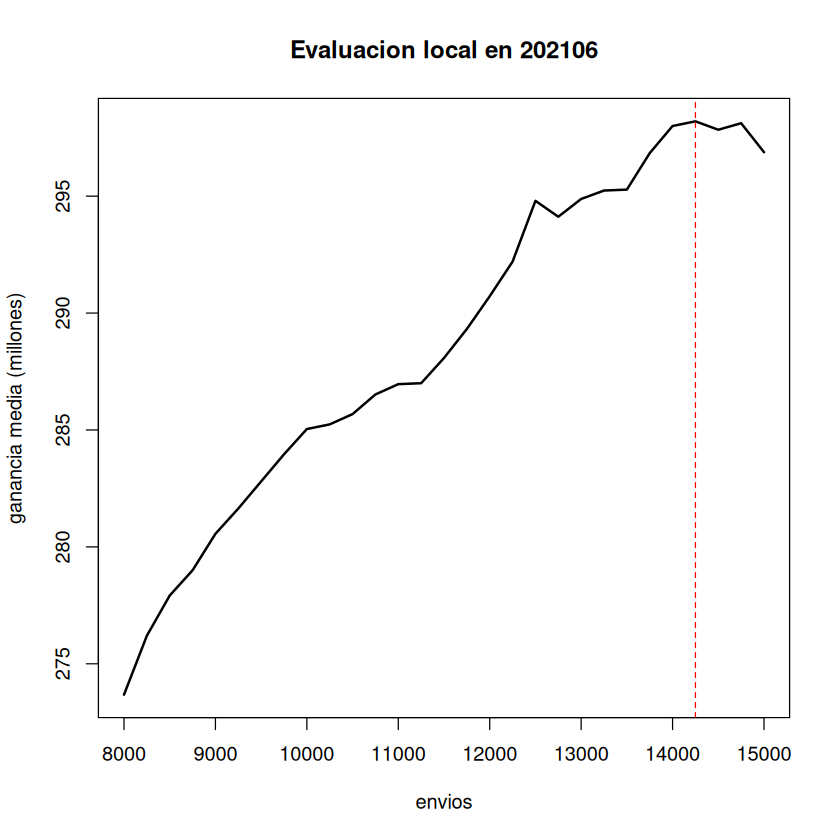

In [28]:
plot(curvas$envios, curvas$media / 1e6, type= "l", lwd= 2,
     xlab= "envios", ylab= "ganancia media (millones)",
     main= paste("Evaluacion local en", PARAM$eval_mes))
abline(v= mejor_envio, lty= 2, col= "red")

## Modelos finales

In [29]:
dtrain_final <- lgb.Dataset(
  data= data.matrix(dataset[foto_mes %in% PARAM$train_final & (azar <= PARAM$trainingstrategy$undersampling_final | clase01 == 1L), campos_buenos, with= FALSE]),
  label= dataset[foto_mes %in% PARAM$train_final & (azar <= PARAM$trainingstrategy$undersampling_final | clase01 == 1L), clase01]
)

dfuture  <- dataset[foto_mes %in% PARAM$future]
X_future <- data.matrix(dfuture[, campos_buenos, with= FALSE])

archivo_pred <- "predicciones_futuro.csv"

if (file.exists(archivo_pred)) {
  tb_pred <- fread(archivo_pred)
  stopifnot( identical(tb_pred$numero_de_cliente, dfuture$numero_de_cliente) )
} else {
  tb_pred <- dfuture[, list(numero_de_cliente)]
}

for (semilla in PARAM$semillas) {
  col_pred <- paste0("pred_", semilla)

  if (col_pred %in% colnames(tb_pred)) {
    cat("Saltando semilla (ya existe):", semilla, "\n")
    next
  }

  modelo <- lgb.train(
    data= dtrain_final,
    param= modifyList(param_normalizado, list(seed= semilla))
  )
  tb_pred[, (col_pred) := predict(modelo, X_future)]

  fwrite(tb_pred, archivo_pred)
  cat(format(Sys.time(), "%X"), "semilla", semilla, "guardada\n")
}

# importancia de variables del ultimo modelo
fwrite(as.data.table(lgb.importance(modelo)), "impo.txt", sep= "\t")
rm(modelo)
gc(full= TRUE, verbose= FALSE)

00:37:38 semilla 864203 guardada
00:38:26 semilla 451997 guardada
00:39:14 semilla 909131 guardada
00:40:01 semilla 582314 guardada
00:40:49 semilla 737281 guardada
00:41:37 semilla 128945 guardada
00:42:25 semilla 675432 guardada
00:43:16 semilla 390217 guardada
00:44:06 semilla 842691 guardada
00:44:56 semilla 519804 guardada


,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2769078,147.9,8380240,447.6,8380240,447.6
Vcells,623586231,4757.6,941113574,7180.2,784146243,5982.6


## Archivos para Zulip


In [30]:
options(scipen= 999)
dir.create("zulip", showWarnings= FALSE)

# cortes alrededor del mejor de la evaluacion local, dentro de [8000, 15000]
if (is.null(PARAM$envios_zulip)) {
  base <- round(mejor_envio / 500) * 500
  PARAM$envios_zulip <- unique(pmin(pmax(seq(base - 1500, base + 1500, by= 500), 8000), 15000))
}
cat("Cortes para Zulip:", PARAM$envios_zulip, "\n")

cols_pred <- grep("^pred_", colnames(tb_pred), value= TRUE)

for (col in cols_pred) {
  ids_ordenados <- tb_pred$numero_de_cliente[ order(-tb_pred[[col]]) ]
  for (envios in PARAM$envios_zulip) {
    archivo <- sprintf("zulip/e%d_N%05d_s%s.csv", PARAM$experimento, envios, sub("pred_", "", col))
    escribir_zulip(ids_ordenados[1:envios], archivo)
  }
}

cat(length(list.files("zulip")), "archivos generados en",
    paste0(getwd(), "/zulip"), "\n")

Cortes para Zulip: 12500 13000 13500 14000 14500 15000 
60 archivos generados en /home/ds/buckets/b1/exp/HT6005/zulip 


**Archivo final:** promedio de las probabilidades de todas las semillas, un solo archivo.
<br>Por defecto usa el mejor corte local. **Cuando sepas qué corte dio mejor en el bot, cambiá `PARAM$envio_final` y volvé a correr esta celda.**

In [31]:
PARAM$envio_final <- mejor_envio   # <- cambiar por el mejor corte segun el bot

tb_pred[, prob_ensamble := rowMeans(.SD), .SDcols= cols_pred]
ids_ensamble <- tb_pred$numero_de_cliente[ order(-tb_pred$prob_ensamble) ]

archivo_final <- sprintf("zulip/FINAL_e%d_N%05d.csv", PARAM$experimento, PARAM$envio_final)
escribir_zulip(ids_ensamble[1:PARAM$envio_final], archivo_final)
tb_pred[, prob_ensamble := NULL]

cat("Archivo final:", archivo_final, "\n")

Archivo final: zulip/FINAL_e6005_N14250.csv 


In [32]:
# control de formato de TODOS los archivos de Zulip
ids_futuro <- dfuture$numero_de_cliente

control <- rbindlist(lapply(list.files("zulip", full.names= TRUE), function(archivo) {
  lineas <- readLines(archivo)
  data.table(
    archivo     = basename(archivo),
    lineas      = length(lineas),
    en_rango    = length(lineas) >= 8000 & length(lineas) <= 15000,
    solo_numeros= all(grepl("^[0-9]+$", lineas)),   # sin encabezado ni notacion cientifica
    sin_repetir = !anyDuplicated(lineas),
    del_futuro  = all(as.numeric(lineas) %in% ids_futuro)
  )
}))

print(control)
if (control[, all(en_rango & solo_numeros & sin_repetir & del_futuro)]) {
  cat("OK: todos los archivos cumplen el formato\n")
} else {
  cat("ATENCION: hay archivos con problemas (ver tabla)\n")
}

                     archivo lineas en_rango solo_numeros sin_repetir
                      <char>  <int>   <lgcl>       <lgcl>      <lgcl>
 1: e6005_N12500_s128945.csv  12500     TRUE         TRUE        TRUE
 2: e6005_N12500_s390217.csv  12500     TRUE         TRUE        TRUE
 3: e6005_N12500_s451997.csv  12500     TRUE         TRUE        TRUE
 4: e6005_N12500_s519804.csv  12500     TRUE         TRUE        TRUE
 5: e6005_N12500_s582314.csv  12500     TRUE         TRUE        TRUE
 6: e6005_N12500_s675432.csv  12500     TRUE         TRUE        TRUE
 7: e6005_N12500_s737281.csv  12500     TRUE         TRUE        TRUE
 8: e6005_N12500_s842691.csv  12500     TRUE         TRUE        TRUE
 9: e6005_N12500_s864203.csv  12500     TRUE         TRUE        TRUE
10: e6005_N12500_s909131.csv  12500     TRUE         TRUE        TRUE
11: e6005_N13000_s128945.csv  13000     TRUE         TRUE        TRUE
12: e6005_N13000_s390217.csv  13000     TRUE         TRUE        TRUE
13: e6005_N13000_s45

In [33]:
write_yaml( PARAM, file= "PARAM.yml")
format(Sys.time(), "%a %b %d %X %Y")

[1] "Wed Oct 07 00:45:13 2026"

##  Archivos FINAL para el bot 

In [34]:
stopifnot(exists("dataset"), exists("param_normalizado"))   # si falla, la sesion se reinicio

filtro_tr <- dataset$foto_mes %in% c(202103, 202104) &
             (dataset$azar <= PARAM$trainingstrategy$undersampling_final | dataset$clase01 == 1L)

dtrain_may <- lgb.Dataset(
  data  = data.matrix(dataset[filtro_tr, campos_buenos, with = FALSE]),
  label = dataset[filtro_tr, clase01]
)
X_may     <- data.matrix(dataset[foto_mes == 202105, campos_buenos, with = FALSE])
baja2_may <- dataset[foto_mes == 202105, clase_ternaria %in% "BAJA+2"]

cortes_may <- seq(8000, 15000, by = 500)
curvas_may <- data.table(envios = cortes_may)

for (s in PARAM$semillas[1:3]) {
  m <- lgb.train(data = dtrain_may, param = modifyList(param_normalizado, list(seed = s)))
  curvas_may[, (paste0("s", s)) := ganancia_acumulada(predict(m, X_may), baja2_may)[cortes_may]]
  cat(format(Sys.time(), "%X"), "semilla", s, "lista\n")
}

curvas_may[, media := rowMeans(.SD), .SDcols = patterns("^s")]
options(scipen = 999)
print(curvas_may[, list(envios, media_millones = round(media / 1e6, 1))])
cat(">> Mejor corte en MAYO:", curvas_may[which.max(media), envios], "\n")

00:45:47 semilla 864203 lista
00:46:17 semilla 451997 lista
00:46:48 semilla 909131 lista
    envios media_millones
     <num>          <num>
 1:   8000          204.8
 2:   8500          204.7
 3:   9000          204.5
 4:   9500          206.8
 5:  10000          206.1
 6:  10500          204.4
 7:  11000          200.3
 8:  11500          198.0
 9:  12000          194.7
10:  12500          191.3
11:  13000          189.3
12:  13500          186.8
13:  14000          182.4
14:  14500          178.3
15:  15000          173.9
>> Mejor corte en MAYO: 9500 


Prueba en zona del sweet spot

In [35]:
options(scipen = 999)
tb_pred   <- fread("predicciones_futuro.csv")
cols_pred <- grep("^pred_", names(tb_pred), value = TRUE)
tb_pred[, prob_ensamble := rowMeans(.SD), .SDcols = cols_pred]
ids_ensamble <- tb_pred$numero_de_cliente[order(-tb_pred$prob_ensamble)]

for (N in seq(9500, 12000, by = 250)) {
  archivo <- sprintf("zulip/FINAL_e6005_N%05d.csv", N)
  writeLines(format(ids_ensamble[1:N], scientific = FALSE, trim = TRUE), archivo)
  cat(archivo, ":", length(readLines(archivo)), "lineas\n")
}

zulip/FINAL_e6005_N09500.csv : 9500 lineas
zulip/FINAL_e6005_N09750.csv : 9750 lineas
zulip/FINAL_e6005_N10000.csv : 10000 lineas
zulip/FINAL_e6005_N10250.csv : 10250 lineas
zulip/FINAL_e6005_N10500.csv : 10500 lineas
zulip/FINAL_e6005_N10750.csv : 10750 lineas
zulip/FINAL_e6005_N11000.csv : 11000 lineas
zulip/FINAL_e6005_N11250.csv : 11250 lineas
zulip/FINAL_e6005_N11500.csv : 11500 lineas
zulip/FINAL_e6005_N11750.csv : 11750 lineas
zulip/FINAL_e6005_N12000.csv : 12000 lineas
